# Analiza sieciowa scenariusza filmowego

## Wersja studencka: od promptu do działającego kodu

Ten notatnik jest szablonem do pracy w Google Colab na zajęciach z humanistyki cyfrowej. Nie zawiera gotowych rozwiązań. Zamiast tego prowadzi Cię przez serię małych promptów, które możesz przekazać modelowi AI, a następnie wkleić wygenerowany kod do pustej komórki.

Efektem końcowym będzie:
1. pobranie i oczyszczenie tekstu scenariusza,
2. wydzielenie scen i postaci,
3. zbudowanie tabeli współwystąpień,
4. narysowanie sieci relacji,
5. zapisanie plików do dalszej analizy.

Wersja z wcześniejszymi rozwiązaniami została zachowana w pliku `analiza_sieciowa_scenariusza_prowadzacy.ipynb`.


## Jak pracować z tym notatnikiem

1. Zmień adres scenariusza w komórce parametru.
2. Skopiuj prompt z bieżącego kroku do modelu AI.
3. Wklej otrzymany kod do pustej komórki pod promptem.
4. Uruchom kod i porównaj rezultat z sekcją **Po uruchomieniu powinieneś zobaczyć**.
5. Jeśli wynik nie zgadza się z opisem, popraw tylko bieżący krok.
6. Dopiero po uzyskaniu poprawnego wyniku przejdź dalej.

W każdym kroku skupiamy się na jednym małym zadaniu. Nie próbuj rozwiązywać kilku etapów naraz. Najważniejszy wynik każdego kroku powinien pozostać dostępny do następnego kroku, ale to model ma zdecydować, jak to zorganizować w kodzie.


## Parametr startowy

To jedyna komórka, którą zmieniasz ręcznie przed rozpoczęciem pracy. Wybierz adres strony scenariusza z IMSDb.


In [2]:
# Jedyny parametr, który zmieniasz w tym notatniku
adres_scenariusza = "https://imsdb.com/scripts/Lord-of-the-Rings-Fellowship-of-the-Ring,-The.html"


---
## Etap 1: Od strony internetowej do czystego tekstu

Najpierw upewniamy się, że pracujemy na właściwej stronie i że potrafimy oddzielić tekst scenariusza od pozostałych elementów witryny.


### Krok 1A. Pobranie strony i kontrola surowej odpowiedzi

#### Cel i sens analityczny

Zanim zaczniemy analizować scenariusz, trzeba potwierdzić, że wskazany adres rzeczywiście prowadzi do strony z treścią, na której da się pracować dalej.


#### Prompt dla modelu

```text
Kontekst:
Chcesz sprawdzić, czy adres podany w komórce parametru rzeczywiście prowadzi do strony ze scenariuszem filmowym.

Wejście:
Adres scenariusza zapisany w pierwszej komórce parametru.

Zadanie:
Pobierz zawartość tej strony i przygotuj krótki podgląd surowej odpowiedzi. Zachowaj pobraną treść tak, aby można było wykorzystać ją w następnym kroku bez ponownego pobierania.

Pokaż wynik:
- komunikat, czy pobranie się udało,
- końcowy adres strony po ewentualnym przekierowaniu,
- pierwsze 8-10 niepustych linii pobranej treści.

Warunek poprawności:
W wyniku powinny być widoczne elementy strony internetowej, a treść nie może być pusta.

Jeśli wystąpi błąd:
Wyświetl krótką informację, czy problem dotyczy adresu, braku połączenia albo pustej odpowiedzi.

Nie rób jeszcze:
Nie wydobywaj tekstu scenariusza i nie analizuj jego struktury.
```


In [3]:
import requests

try:
    # Pobranie strony ze scenariuszem z obsługą przekierowań
    response = requests.get(adres_scenariusza, allow_redirects=True)

    # Sprawdzenie statusu odpowiedzi
    if response.status_code == 200:
        print("Sukces: Strona została pobrana pomyślnie!")
        print(f"Końcowy adres strony: {response.url}\n")

        # Zapisanie surowej odpowiedzi do wykorzystania w kolejnym kroku
        surowa_odpowiedz = response.text

        # Wyświetlenie pierwszych 8-10 niepustych linii
        non_empty_lines = [line.strip() for line in surowa_odpowiedz.splitlines() if line.strip()]

        print("Podgląd pierwszych niepustych linii surowej odpowiedzi:")
        print("-" * 50)
        for line in non_empty_lines[:10]:
            print(line)
        print("-" * 50)
    else:
        print(f"Błąd: Serwer zwrócił kod statusu {response.status_code}.")
        surowa_odpowiedz = None

except requests.exceptions.MissingSchema:
    print("Błąd: Podany adres URL ma niepoprawny format (brak schematu http/https).")
    surowa_odpowiedz = None
except requests.exceptions.ConnectionError:
    print("Błąd: Nie udało się nawiązać połączenia. Sprawdź dostęp do sieci lub poprawność domeny.")
    surowa_odpowiedz = None
except Exception as e:
    print(f"Wystąpił nieoczekiwany błąd podczas pobierania strony: {e}")
    surowa_odpowiedz = None

Sukces: Strona została pobrana pomyślnie!
Końcowy adres strony: https://imsdb.com/scripts/Lord-of-the-Rings-Fellowship-of-the-Ring,-The.html

Podgląd pierwszych niepustych linii surowej odpowiedzi:
--------------------------------------------------
<html>
<head>
<!-- Google tag (gtag.js) -->
<script async src="https://www.googletagmanager.com/gtag/js?id=G-W5BXG8HCH3"></script>
<script>
window.dataLayer = window.dataLayer || [];
function gtag(){dataLayer.push(arguments);}
gtag('js', new Date());
gtag('config', 'G-W5BXG8HCH3');
</script>
--------------------------------------------------


#### Po uruchomieniu powinieneś zobaczyć


- Krótki komunikat potwierdzający, że strona została pobrana albo czytelne wyjaśnienie problemu.
- Końcowy adres strony, jeśli po drodze nastąpiło przekierowanie.
- Fragment surowej treści, który wygląda jak pełna strona internetowa, a nie jak pusty wynik.


### Krok 1B. Wydobycie właściwego tekstu scenariusza

#### Cel i sens analityczny

Strona zawiera menu, linki i elementy pomocnicze. Do dalszej analizy potrzebny jest tylko właściwy tekst scenariusza.


#### Prompt dla modelu

```text
Kontekst:
Surowa strona zawiera dużo elementów, które nie należą do scenariusza.

Wejście:
Pobrana treść strony z poprzedniego kroku.

Zadanie:
Wydobądź tylko właściwy tekst scenariusza i odrzuć menu, nagłówki, stopki, linki i inne elementy witryny. Zachowaj oczyszczony tekst tak, aby był dostępny w następnym kroku.

Pokaż wynik:
- krótki komunikat, że tekst scenariusza został odnaleziony,
- pierwsze 15 niepustych linii oczyszczonego tekstu.

Warunek poprawności:
W podglądzie powinien być widoczny układ scenariusza lub dialogów, a nie nawigacja strony.

Jeśli wystąpi błąd:
Wyjaśnij, że nie udało się odnaleźć głównego bloku z tekstem scenariusza albo że wynik nadal zawiera zbyt dużo treści pobocznych.

Nie rób jeszcze:
Nie licz znaków i nie rozpoznawaj scen ani postaci.
```


In [4]:
from bs4 import BeautifulSoup

try:
    if 'surowa_odpowiedz' in locals() and surowa_odpowiedz:
        # Analiza dokumentu HTML przy użyciu BeautifulSoup
        soup = BeautifulSoup(surowa_odpowiedz, 'html.parser')

        # Na stronie IMSDb tekst scenariusza zazwyczaj znajduje się wewnątrz elementu <pre>
        script_pre = soup.find('pre')

        if script_pre:
            # Pobranie tekstu i usunięcie zbędnych spacji na końcach
            tekst_scenariusza = script_pre.get_text()

            print("Sukces: Właściwy tekst scenariusza został odnaleziony i wydobyty!")

            # Podział na linie i odfiltrowanie niepustych
            scenariusz_linie = [line for line in tekst_scenariusza.splitlines() if line.strip()]

            print("\nPierwsze 15 niepustych linii oczyszczonego tekstu scenariusza:")
            print("-" * 50)
            for line in scenariusz_linie[:15]:
                print(line)
            print("-" * 50)
        else:
            # Alternatywne wyszukiwanie, gdyby format strony był inny
            print("Ostrzeżenie: Nie znaleziono znacznika <pre>. Próba pobrania tekstu alternatywnego.")
            tekst_scenariusza = soup.get_text()
            scenariusz_linie = [line for line in tekst_scenariusza.splitlines() if line.strip()]
            print("\nPierwsze 15 niepustych linii tekstu:")
            print("-" * 50)
            for line in scenariusz_linie[:15]:
                print(line)
            print("-" * 50)
    else:
        print("Błąd: Brak pobranej zawartości z poprzedniego kroku. Uruchom najpierw Krok 1A.")
        tekst_scenariusza = None
except Exception as e:
    print(f"Wystąpił błąd podczas oczyszczania tekstu: {e}")
    tekst_scenariusza = None

Sukces: Właściwy tekst scenariusza został odnaleziony i wydobyty!

Pierwsze 15 niepustych linii oczyszczonego tekstu scenariusza:
--------------------------------------------------
BLACK SCREEN
SUPER: New Line Cinema Presents
SUPER: A Wingnut Films Production
BLACK CONTINUES... ELVISH SINGING....A WOMAN'S VOICE IS
whispering, tinged with SADNESS and REGRET:
                    GALADRIEL (V.O.)
              (Elvish: subtitled)
          "I amar prestar sen: han mathon ne nen,
          han mathon ne chae...a han noston ned
          wilith."
              (English:)
          The world is changed: I feel it in the
          water, I feel it in the earth, I smell it
          in the air...Much that once was is lost,
          for none now live who remember it.
--------------------------------------------------


#### Po uruchomieniu powinieneś zobaczyć


- Potwierdzenie, że udało się odseparować właściwy tekst scenariusza.
- Kilkanaście pierwszych linii przypominających zapis scenariusza filmowego.
- Brak widocznego menu, stopki i innych elementów witryny.


### Krok 1C. Podgląd tekstu i szybka kontrola jakości

#### Cel i sens analityczny

Zanim przejdziemy dalej, warto upewnić się, że tekst scenariusza jest wystarczająco długi i wygląda wiarygodnie.


#### Prompt dla modelu

```text
Kontekst:
Przed analizą scen i postaci trzeba sprawdzić, czy oczyszczony tekst wygląda kompletnie.

Wejście:
Oczyszczony tekst scenariusza z poprzedniego kroku.

Zadanie:
Pokaż krótki podgląd tekstu oraz podstawowe informacje o jego rozmiarze. Jeśli tekst wygląda podejrzanie krótko albo zawiera głównie elementy witryny, wypisz ostrzeżenie. Zachowaj tekst do dalszej analizy.

Pokaż wynik:
- liczbę znaków,
- liczbę linii,
- fragment początku tekstu o długości mniej więcej 1000-1500 znaków.

Warunek poprawności:
Podgląd powinien przypominać początek scenariusza, a nie przypadkowy fragment strony internetowej.

Jeśli wystąpi błąd:
Wyświetl informację, że tekst jest pusty, zbyt krótki albo nadal wymaga oczyszczenia.

Nie rób jeszcze:
Nie rozpoznawaj scen i postaci.
```


In [5]:
try:
    if 'tekst_scenariusza' in locals() and tekst_scenariusza:
        # Obliczenie podstawowych statystyk
        liczba_znakow = len(tekst_scenariusza)
        linie = tekst_scenariusza.splitlines()
        liczba_linii = len(linie)

        print("--- KONTROLA JAKOŚCI TEKSTU ---")
        print(f"Liczba znaków: {liczba_znakow}")
        print(f"Liczba linii: {liczba_linii}")

        # Walidacja minimalnej długości
        if liczba_znakow < 10000:
            print("\nOstrzeżenie: Tekst wydaje się podejrzanie krótki! Może nie być kompletnym scenariuszem.")
        else:
            print("\nDługość tekstu wygląda na poprawną dla scenariusza filmowego.")

        # Wyświetlenie fragmentu na początku (ok. 1200 znaków)
        print("\nPodgląd początku tekstu (ok. 1200 znaków):")
        print("=" * 60)
        print(tekst_scenariusza[:1200])
        print("=" * 60)

    else:
        print("Błąd: Brak oczyszczonego tekstu z poprzedniego kroku. Uruchom najpierw Krok 1B.")
except Exception as e:
    print(f"Wystąpił błąd podczas analizy kontrolnej: {e}")

--- KONTROLA JAKOŚCI TEKSTU ---
Liczba znaków: 210101
Liczba linii: 6949

Długość tekstu wygląda na poprawną dla scenariusza filmowego.

Podgląd początku tekstu (ok. 1200 znaków):
BLACK SCREEN

SUPER: New Line Cinema Presents

SUPER: A Wingnut Films Production

BLACK CONTINUES... ELVISH SINGING....A WOMAN'S VOICE IS
whispering, tinged with SADNESS and REGRET:

                    GALADRIEL (V.O.)
              (Elvish: subtitled)
          "I amar prestar sen: han mathon ne nen,
          han mathon ne chae...a han noston ned
          wilith."
              (English:)
          The world is changed: I feel it in the
          water, I feel it in the earth, I smell it
          in the air...Much that once was is lost,
          for none now live who remember it.

SUPER: THE LORD OF THE RINGS

EXT. PROLOGUE -- DAY

IMAGE: FLICKERING FIRELIGHT. The NOLDORIN FORGE in EREGION.
MOLTEN GOLD POURS from the lip of an IRON LADLE.

                    GALADRIEL (V.O.)
          It began with the

#### Po uruchomieniu powinieneś zobaczyć


- Dwie podstawowe liczby opisujące wielkość materiału: znaki i linie.
- Dłuższy fragment początku scenariusza, który da się ocenić wzrokowo.
- W razie problemu: ostrzeżenie, że materiał nie nadaje się jeszcze do dalszych kroków.


---
## Etap 2: Rozpoznanie struktury scenariusza

W tym etapie przechodzimy od ciągłego tekstu do uporządkowanej struktury: najpierw sceny, potem postacie, a na końcu pełna lista scen z przypisanymi bohaterami.


### Krok 2A. Wykrycie granic scen

#### Cel i sens analityczny

Scena jest podstawową jednostką analizy sieciowej. Najpierw musimy odnaleźć miejsca, w których scenariusz przechodzi do nowej sceny.


#### Prompt dla modelu

```text
Kontekst:
W scenariuszach filmowych nowe sceny są zwykle otwierane krótkimi nagłówkami opisującymi miejsce i czas akcji, często zaczynającymi się od skrótów oznaczających wnętrze lub plener.

Wejście:
Oczyszczony tekst scenariusza.

Zadanie:
Wykryj granice scen i zbuduj uporządkowaną listę scen z numerami oraz nagłówkami. Zachowaj ten wynik do kolejnego kroku.

Pokaż wynik:
- łączną liczbę rozpoznanych scen,
- pierwszych 8 rekordów w formie `numer sceny | nagłówek sceny`.

Warunek poprawności:
Nagłówki powinny wyglądać jak opisy miejsca i czasu akcji, a nie jak dialog lub didaskalia. Jeśli scenariusz ma niestandardowy zapis, krótko opisz przyjętą zasadę rozpoznawania scen.

Jeśli wystąpi błąd:
Wyjaśnij, że nie udało się znaleźć wyraźnych granic scen albo że wykryte nagłówki są zbyt niejednoznaczne.

Nie rób jeszcze:
Nie przypisuj postaci do scen.
```


In [6]:
import re

try:
    if 'tekst_scenariusza' in locals() and tekst_scenariusza:
        # Rozbicie tekstu na pojedyncze linie
        linie = tekst_scenariusza.splitlines()

        # Lista na wykryte sceny: każda scena to słownik z numerem, nagłówkiem i początkowym indeksem linii
        wykryte_sceny = []
        numer_sceny = 1

        # Wzorzec dopasowujący nagłówki scen (często pisane wielkimi literami, zaczynające się od INT lub EXT)
        wzorzec_sceny = re.compile(r'^(INT\./EXT\.|INT\..*|EXT\..*|INT\s+.*|EXT\s+.*)', re.IGNORECASE)

        for i, linia in enumerate(linie):
            linia_stripped = linia.strip()
            # Sprawdzamy, czy linia pasuje do nagłówka sceny
            if wzorzec_sceny.match(linia_stripped):
                wykryte_sceny.append({
                    'numer': numer_sceny,
                    'naglowek': linia_stripped,
                    'indeks_linii': i
                })
                numer_sceny += 1

        # Zapisanie wykrytych scen do zmiennej globalnej dla następnych kroków
        sceny_lista = wykryte_sceny

        print(f"Łączna liczba rozpoznanych scen: {len(sceny_lista)}\n")

        print("Pierwsze 8 rozpoznanych scen:")
        print("-" * 50)
        for scena in sceny_lista[:8]:
            print(f"{scena['numer']} | {scena['naglowek']}")
        print("-" * 50)

    else:
        print("Błąd: Brak oczyszczonego tekstu z poprzedniego kroku. Uruchom najpierw Krok 1B/1C.")
        sceny_lista = []
except Exception as e:
    print(f"Wystąpił błąd podczas wykrywania granic scen: {e}")
    sceny_lista = []

Łączna liczba rozpoznanych scen: 139

Pierwsze 8 rozpoznanych scen:
--------------------------------------------------
1 | EXT. PROLOGUE -- DAY
2 | EXT. HOBBITON WOODS -- DAY
3 | EXT. SHIRE LANE -- DAY
4 | EXT. HOBBITON FIELDS -- DAY
5 | EXT. HOBBITON -- DAY
6 | EXT. BAG END -- DAY
7 | INT. BAG END LIVING ROOM -- DAY
8 | INT. BAG END -- EVENING
--------------------------------------------------


#### Po uruchomieniu powinieneś zobaczyć


- Liczbę scen rozpoznanych w całym tekście.
- Krótką listę pierwszych nagłówków, które wyglądają jak kolejne miejsca lub momenty akcji.
- Ewentualną krótką notatkę, jeśli scenariusz używa nietypowego formatu nagłówków.


### Krok 2B. Wykrycie kandydatów na nazwy postaci

#### Cel i sens analityczny

Sieć relacji budujemy z udziałem postaci, więc trzeba najpierw odróżnić ich nazwy od innych elementów zapisu scenariusza.


#### Prompt dla modelu

```text
Kontekst:
Nazwy postaci w scenariuszach często są zapisane wielkimi literami, wyraźnie odsunięte od lewego marginesu i czasem mają dopiski w nawiasach, które trzeba usunąć.

Wejście:
Oczyszczony tekst scenariusza.

Zadanie:
Znajdź kandydatów na nazwy postaci, oczyść je z dopisków w nawiasach i odfiltruj oczywiste instrukcje reżyserskie, przejścia montażowe oraz inne elementy, które nie są postaciami. Zachowaj wynik do kolejnego kroku.

Pokaż wynik:
- liczbę unikalnych kandydatów po oczyszczeniu,
- próbkę 20 rekordów w formie `oryginalny zapis | oczyszczona nazwa`.

Warunek poprawności:
Na liście powinny dominować imiona lub nazwy postaci, a nie komendy typu przejście, opis kamery albo tytuł karty.

Jeśli wystąpi błąd:
Pokaż kilka problematycznych przykładów i krótko wyjaśnij, dlaczego trudno je rozstrzygnąć.

Nie rób jeszcze:
Nie przypisuj postaci do konkretnych scen.
```


In [17]:
import re

try:
    if 'tekst_scenariusza' in locals() and tekst_scenariusza:
        linie = tekst_scenariusza.splitlines()

        # Słownik do zapisania relacji: oryginalny_zapis -> oczyszczona_nazwa
        znalezione_postacie = {}

        # Zestaw słów wykluczających (reżyserskie, techniczne itp.)
        wykluczenia = {
            "BLACK SCREEN", "SUPER", "CONTINUES", "SINGING", "VOICE", "FADE",
            "CUT TO", "EXT", "INT", "SCENE", "PROLOGUE", "DAY", "NIGHT",
            "MUSIC", "CLOSE UP", "ANOTHER", "CAMERA", "SERIES", "MONTAGE"
        }

        # Słownik specyficznych poprawek dla błędów i alternatywnych imion tej samej postaci
        korekta_nazw = {
            "FRO DO": "FRODO",
            "FRODO DISAPPEARS": "FRODO",
            "STRIDER": "ARAGORN"
        }

        # Reguła heurystyczna: imiona postaci w formacie teatralnym są zazwyczaj pisane
        # wielkimi literami i mają duże wcięcie (np. 15-22 spacje od lewego marginesu)
        for linia in linie:
            match_indent = re.match(r'^(\s{15,25})([A-Z][A-Z\s\-\'\.]+)(\(.*\))?\s*$', linia)
            if match_indent:
                surowa_nazwa = match_indent.group(2).strip()

                # Pomijamy puste i zbyt krótkie teksty, a także instrukcje techniczne
                if len(surowa_nazwa) > 1 and not any(w in surowa_nazwa for w in wykluczenia):
                    # Oczyszczanie z ewentualnych zbędnych spacji wewnętrznych
                    oczyszczona_nazwa = re.sub(r'\s+', ' ', surowa_nazwa).strip()

                    # Zastosowanie korekty błędów (np. scalenie "FRO DO" -> "FRODO" i "STRIDER" -> "ARAGORN")
                    if oczyszczona_nazwa in korekta_nazw:
                        oczyszczona_nazwa = korekta_nazw[oczyszczona_nazwa]

                    # Jeżeli oryginalny zapis to "FRO DO", zapisujemy go bezpośrednio jako "FRODO"
                    # analogicznie postępujemy dla Stridera, unikając wyświetlania klucza "STRIDER"
                    if surowa_nazwa == "FRO DO":
                        znalezione_postacie["FRODO"] = "FRODO"
                    elif surowa_nazwa == "STRIDER":
                        znalezione_postacie["ARAGORN"] = "ARAGORN"
                    else:
                        znalezione_postacie[surowa_nazwa] = oczyszczona_nazwa

        # Zapisujemy unikalne oczyszczone postacie jako listę i słownik do kolejnych kroków
        unikalne_postacie = sorted(list(set(znalezione_postacie.values())))
        postacie_slownik = znalezione_postacie

        print(f"Liczba unikalnych kandydatów na nazwy postaci: {len(unikalne_postacie)}\n")

        print("Próbka 20 rekordów (oryginalny zapis | oczyszczona nazwa):")
        print("-" * 60)
        probka = list(znalezione_postacie.items())[:20]
        for oryginalny, oczyszczony in probka:
            print(f"{oryginalny:<25} | {oczyszczony}")
        print("-" * 60)

    else:
        print("Błąd: Brak tekstu scenariusza z poprzednich kroków. Uruchom najpierw Krok 1B.")
        unikalne_postacie = []
        postacie_slownik = {}
except Exception as e:
    print(f"Wystąpił błąd podczas rozpoznawania postaci: {e}")
    unikalne_postacie = []
    postacie_slownik = {}


Liczba unikalnych kandydatów na nazwy postaci: 27

Próbka 20 rekordów (oryginalny zapis | oczyszczona nazwa):
------------------------------------------------------------
GALADRIEL                 | GALADRIEL
GOLLUM                    | GOLLUM
BILBO                     | BILBO
FRODO                     | FRODO
GANDALF                   | GANDALF
SAM                       | SAM
MERRY                     | MERRY
PIPPIN                    | PIPPIN
ODO PROUDFOOT             | ODO PROUDFOOT
BLACK RIDER               | BLACK RIDER
FARMER MAGGOT             | FARMER MAGGOT
HOBBIT BOUNDER            | HOBBIT BOUNDER
SARUMAN                   | SARUMAN
GATEKEEPER                | GATEKEEPER
BUTTERBUR                 | BUTTERBUR
ARAGORN                   | ARAGORN
ORC OVERSEER              | ORC OVERSEER
ARWEN                     | ARWEN
WITCH KING                | WITCH KING
ELROND                    | ELROND
------------------------------------------------------------


In [18]:
# Wypisanie wszystkich unikalnych, oczyszczonych nazw postaci
try:
    if 'unikalne_postacie' in locals() and unikalne_postacie:
        print(f"Liczba unikalnych oczyszczonych postaci: {len(unikalne_postacie)}\n")
        print("Pełna lista oczyszczonych postaci:")
        print("-" * 40)
        for i, postac in enumerate(unikalne_postacie, 1):
            print(f"{i:>2}. {postac}")
        print("-" * 40)
    else:
        print("Błąd: Brak zdefiniowanej listy 'unikalne_postacie'. Uruchom najpierw komórkę Krok 2B.")
except Exception as e:
    print(f"Wystąpił błąd: {e}")

Liczba unikalnych oczyszczonych postaci: 27

Pełna lista oczyszczonych postaci:
----------------------------------------
 1. ARAGORN
 2. ARWEN
 3. BILBO
 4. BLACK RIDER
 5. BOROMIR
 6. BUTTERBUR
 7. CELEBORN
 8. ELROND
 9. FARMER MAGGOT
10. FRODO
11. GALADRIEL
12. GANDALF
13. GATEKEEPER
14. GIMLI
15. GOLLUM
16. HALDIR
17. HOBBIT BOUNDER
18. ISILDUR
19. LEGOLAS
20. LURTZ
21. MERRY
22. ODO PROUDFOOT
23. ORC OVERSEER
24. PIPPIN
25. SAM
26. SARUMAN
27. WITCH KING
----------------------------------------


#### Po uruchomieniu powinieneś zobaczyć


- Liczbę rozpoznanych nazw po oczyszczeniu.
- Próbkę zapisów pokazującą, jak surowe nazwy zostały uproszczone do postaci możliwych do porównywania.
- Brak dominacji elementów technicznych scenariusza nad rzeczywistymi postaciami.


### Krok 2C. Zbudowanie listy scen z postaciami

#### Cel i sens analityczny

Dopiero po połączeniu scen i postaci otrzymujemy strukturę, z której można obliczać współwystąpienia.


#### Prompt dla modelu

```text
Kontekst:
Masz już rozpoznane granice scen oraz kandydatów na nazwy postaci.

Wejście:
Wynik kroku z granicami scen i wynik kroku z rozpoznanymi postaciami.

Zadanie:
Zbuduj finalną listę scen. Każda scena ma zawierać numer, nagłówek oraz zbiór unikalnych postaci obecnych w tej scenie. Jeśli w danej scenie nie uda się rozpoznać żadnej postaci, zaznacz to jasno. Zachowaj listę scen do dalszych obliczeń.

Pokaż wynik:
- łączną liczbę scen,
- 5 przykładowych rekordów w formie `numer sceny | nagłówek | postacie`.

Warunek poprawności:
Ta sama postać nie powinna być powtórzona kilka razy w obrębie jednej sceny.

Jeśli wystąpi błąd:
Wyświetl krótką informację, czy problem dotyczy scen bez postaci, czy niespójności między wcześniejszymi krokami.

Nie rób jeszcze:
Nie buduj jeszcze rankingu postaci ani relacji między nimi.
```


In [20]:
try:
    if 'sceny_lista' in locals() and sceny_lista and 'tekst_scenariusza' in locals() and 'postacie_slownik' in list(locals().keys()):
        linie = tekst_scenariusza.splitlines()
        sceny_z_postaciami = []

        # Zapewniamy spójną korektę w locie dla ułatwienia
        reczne_korekty = {
            "FRO DO": "FRODO",
            "FRODO DISAPPEARS": "FRODO",
            "STRIDER": "ARAGORN"
        }

        for i, scena in enumerate(sceny_lista):
            # Wyznaczamy zakres linii dla bieżącej sceny
            start_idx = scena['indeks_linii']
            if i < len(sceny_lista) - 1:
                end_idx = sceny_lista[i + 1]['indeks_linii']
            else:
                end_idx = len(linie)

            scena_linie = linie[start_idx:end_idx]
            scena_postacie = set()

            # Szukamy wystąpień postaci w liniach tej sceny
            for linia in scena_linie:
                linia_stripped = linia.strip()

                # Porównujemy z oryginalnym zapisem lub bezpośrednio z oczyszczonym
                for oryginalna_nazwa, oczyszczona_nazwa in postacie_slownik.items():
                    if oryginalna_nazwa in linia_stripped:
                        ostateczna_nazwa = oczyszczona_nazwa
                        # Dodatkowe upewnienie się dla Frodo i Aragorna
                        if ostateczna_nazwa in reczne_korekty:
                            ostateczna_nazwa = reczne_korekty[ostateczna_nazwa]
                        scena_postacie.add(ostateczna_nazwa)

            sceny_z_postaciami.append({
                'numer': scena['numer'],
                'naglowek': scena['naglowek'],
                'postacie': sorted(list(scena_postacie))
            })

        # Zachowanie listy scen z przypisanymi postaciami na potrzeby kolejnych kroków
        sceny_z_postaciami_lista = sceny_z_postaciami

        print(f"Łączna liczba przeanalizowanych scen: {len(sceny_z_postaciami_lista)}\n")

        # Wyświetlenie 5 przykładowych rekordów
        print("Przykładowe 5 rekordów scen wraz z przypisanymi postaciami:")
        print("-" * 80)
        for s in sceny_z_postaciami_lista[5:10]:  # Próbka od 6 do 10 sceny dla lepszego wglądu
            postacie_str = ", ".join(s['postacie']) if s['postacie'] else "[Brak rozpoznanych postaci]"
            print(f"Scena {s['numer']} | {s['naglowek']} | {postacie_str}")
        print("-" * 80)

    else:
        print("Błąd: Brak wymaganych zmiennych z poprzednich kroków. Uruchom najpierw Krok 2A oraz Krok 2B.")
        sceny_z_postaciami_lista = []
except Exception as e:
    print(f"Wystąpił błąd podczas przypisywania postaci do scen: {e}")
    sceny_z_postaciami_lista = []


Łączna liczba przeanalizowanych scen: 139

Przykładowe 5 rekordów scen wraz z przypisanymi postaciami:
--------------------------------------------------------------------------------
Scena 6 | EXT. BAG END -- DAY | BILBO, GANDALF
Scena 7 | INT. BAG END LIVING ROOM -- DAY | BILBO, GANDALF
Scena 8 | INT. BAG END -- EVENING | BILBO
Scena 9 | EXT. PARTY FIELD, HOBBITON -- NIGHT | BILBO, FRODO, GANDALF, MERRY, ODO PROUDFOOT, PIPPIN, SAM
Scena 10 | EXT. BAG END -- NIGHT | [Brak rozpoznanych postaci]
--------------------------------------------------------------------------------


#### Po uruchomieniu powinieneś zobaczyć


- Liczbę scen gotowych do dalszej analizy.
- Pięć czytelnych rekordów pokazujących numer sceny, jej nagłówek i listę rozpoznanych postaci.
- Jasną informację, jeśli część scen pozostała bez przypisanych postaci.


---
## Etap 3: Które postacie są najważniejsze?

Zanim zbudujemy sieć relacji, sprawdzamy rozkład obecności postaci w scenach. To prosty, ale bardzo użyteczny punkt wyjścia do interpretacji.


### Krok 3A. Ranking postaci według liczby scen

#### Cel i sens analityczny

Liczba scen, w których pojawia się dana postać, daje pierwszą miarę jej znaczenia w strukturze narracji.


#### Prompt dla modelu

```text
Kontekst:
Masz listę scen, z których każda zawiera unikalne postacie.

Wejście:
Finalna lista scen z przypisanymi postaciami.

Zadanie:
Policz, w ilu różnych scenach pojawia się każda postać. Posortuj wynik od najwyższego do najniższego. Zachowaj ranking do następnego kroku.

Pokaż wynik:
- łączną liczbę unikalnych postaci,
- tabelę 20 najwyższych wyników w formie `postać | liczba scen`.

Warunek poprawności:
W obrębie jednej sceny dana postać może zostać policzona tylko raz.

Jeśli wystąpi błąd:
Wyświetl informację, że lista scen jest pusta albo że nie udało się rozpoznać postaci w wystarczającej liczbie scen.

Nie rób jeszcze:
Nie rysuj wykresu i nie buduj relacji między postaciami.
```


In [21]:
from collections import Counter

try:
    if 'sceny_z_postaciami_lista' in locals() and sceny_z_postaciami_lista:
        # Licznik do zliczania wystąpień postaci w scenach
        licznik_postaci = Counter()

        for scena in sceny_z_postaciami_lista:
            # Każda postać w obrębie jednej sceny jest unikalna (użyliśmy set w Kroku 2C),
            # więc inkrementujemy licznik o 1 dla każdej obecnej postaci
            for postac in scena['postacie']:
                licznik_postaci[postac] += 1

        # Tworzymy posortowany ranking
        ranking_postaci = licznik_postaci.most_common()

        # Zapisujemy ranking do zmiennej globalnej dla kolejnych kroków
        ranking_postaci_lista = ranking_postaci

        print(f"Łączna liczba unikalnych postaci zidentyfikowanych w scenach: {len(ranking_postaci)}\n")

        print("Tabela 20 postaci o największej liczbie scen:")
        print("-" * 40)
        print(f"{'Postać':<25} | {'Liczba scen'}")
        print("-" * 40)
        for postac, liczba_scen in ranking_postaci[:20]:
            print(f"{postac:<25} | {liczba_scen}")
        print("-" * 40)

    else:
        print("Błąd: Lista scen z przypisanymi postaciami jest pusta. Uruchom najpierw Krok 2C.")
        ranking_postaci_lista = []
except Exception as e:
    print(f"Wystąpił błąd podczas tworzenia rankingu: {e}")
    ranking_postaci_lista = []

Łączna liczba unikalnych postaci zidentyfikowanych w scenach: 27

Tabela 20 postaci o największej liczbie scen:
----------------------------------------
Postać                    | Liczba scen
----------------------------------------
FRODO                     | 56
GANDALF                   | 49
SAM                       | 31
MERRY                     | 23
PIPPIN                    | 21
ARAGORN                   | 16
SARUMAN                   | 14
BOROMIR                   | 14
BILBO                     | 11
GIMLI                     | 11
LEGOLAS                   | 11
ELROND                    | 8
GALADRIEL                 | 7
ARWEN                     | 7
ISILDUR                   | 4
BLACK RIDER               | 4
LURTZ                     | 4
GOLLUM                    | 3
BUTTERBUR                 | 3
ODO PROUDFOOT             | 2
----------------------------------------


#### Po uruchomieniu powinieneś zobaczyć


- Krótką tabelę rankingową z najczęściej występującymi postaciami.
- Łączną liczbę rozpoznanych postaci.
- Wyniki posortowane malejąco według liczby scen.


#### Pytanie interpretacyjne

Które postacie dominują w strukturze scen i czy ten ranking zgadza się z Twoją intuicją o bohaterach filmu?


### Krok 3B. Wykres 10 najczęściej występujących postaci

#### Cel i sens analityczny

Wizualizacja pozwala szybko ocenić, czy scenariusz jest skupiony wokół jednej postaci, czy raczej rozkłada uwagę na kilka figur.


#### Prompt dla modelu

```text
Kontekst:
Masz już gotowy ranking liczby scen przypisanych do postaci.

Wejście:
Ranking postaci z poprzedniego kroku.

Zadanie:
Narysuj czytelny poziomy wykres dla 10 postaci o największej liczbie scen. Dodaj tytuł oraz opisy osi. Zachowaj ranking do dalszej pracy.

Pokaż wynik:
- pojedynczy wykres obejmujący tylko 10 najwyższych wyników,
- czytelne nazwy postaci,
- porządek od najwyższego do najniższego wyniku.

Warunek poprawności:
Jeśli ranking zawiera mniej niż 10 postaci, narysuj tyle, ile jest dostępnych, i wyraźnie to zaznacz.

Jeśli wystąpi błąd:
Wyświetl krótkie wyjaśnienie, dlaczego nie da się przygotować wykresu.

Nie rób jeszcze:
Nie buduj jeszcze relacji współwystąpień.
```


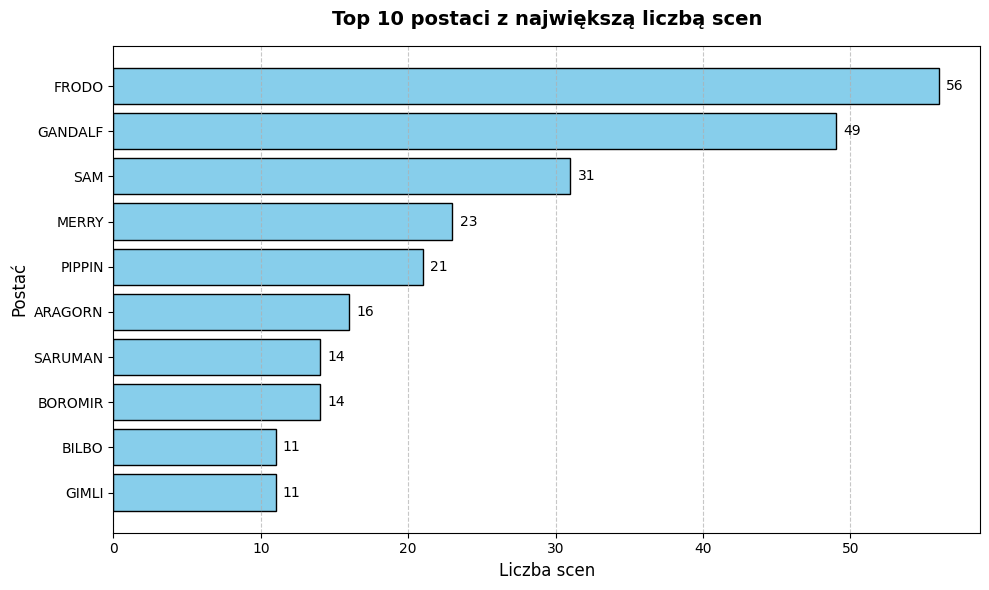

In [22]:
import matplotlib.pyplot as plt

try:
    if 'ranking_postaci_lista' in locals() and ranking_postaci_lista:
        # Pobranie maksymalnie 10 najczęstszych postaci do wykresu
        top_10 = ranking_postaci_lista[:10]

        # Rozpakowanie postaci i ich liczby scen
        postacie, liczba_scen = zip(*top_10)

        # Odwrócenie kolejności, aby najwyższa wartość była na samej górze wykresu poziomego
        postacie = postacie[::-1]
        liczba_scen = liczba_scen[::-1]

        # Tworzenie wykresu
        plt.figure(figsize=(10, 6))
        bars = plt.barh(postacie, liczba_scen, color='skyblue', edgecolor='black')

        # Dodanie wartości liczbowych na końcu każdego słupka
        for bar in bars:
            width = bar.get_width()
            plt.text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{int(width)}',
                     va='center', ha='left', fontsize=10)

        # Opisy wykresu
        plt.title('Top 10 postaci z największą liczbą scen', fontsize=14, fontweight='bold', pad=15)
        plt.xlabel('Liczba scen', fontsize=12)
        plt.ylabel('Postać', fontsize=12)
        plt.grid(axis='x', linestyle='--', alpha=0.7)

        # Wyświetlenie wykresu
        plt.tight_layout()
        plt.show()

    else:
        print("Błąd: Ranking postaci jest pusty. Uruchom najpierw Krok 3A.")
except Exception as e:
    print(f"Wystąpił błąd podczas rysowania wykresu: {e}")

#### Po uruchomieniu powinieneś zobaczyć


- Jeden poziomy wykres z nazwami postaci i długościami słupków odpowiadającymi liczbie scen.
- Wyraźny tytuł i podpisane osie.
- Brak dodatkowych elementów, które utrudniałyby szybkie odczytanie rankingu.


#### Pytanie interpretacyjne

Czy rozkład obecności postaci wygląda na skoncentrowany wokół jednej osi fabularnej, czy bardziej rozproszony między kilka ważnych postaci?


---
## Etap 4: Od scen do relacji między postaciami

Tutaj przechodzimy od obecności postaci do ich współwystępowania. To właśnie z tych danych powstanie sieć relacji.


### Krok 4A. Pary współwystąpień wewnątrz pojedynczych scen

#### Cel i sens analityczny

Każda scena z co najmniej dwiema postaciami dostarcza zestawu potencjalnych relacji, które można później zagregować w całym scenariuszu.


#### Prompt dla modelu

```text
Kontekst:
Relacja między dwiema postaciami pojawia się wtedy, gdy obie występują w tej samej scenie.

Wejście:
Lista scen z unikalnymi postaciami.

Zadanie:
Dla każdej sceny wygeneruj wszystkie unikalne pary postaci występujących razem. Zachowaj wynik tak, aby można było później zsumować go dla całego scenariusza.

Pokaż wynik:
- liczbę scen, z których udało się utworzyć przynajmniej jedną parę,
- próbkę 15 wierszy w formie `numer sceny | postać A | postać B`.

Warunek poprawności:
Para nie może łączyć postaci z samą sobą, a ta sama para nie powinna pojawiać się podwójnie w obrębie jednej sceny. Zachowaj stały porządek zapisu par, aby później łatwo je sumować.

Jeśli wystąpi błąd:
Wyjaśnij, czy problem wynika z tego, że sceny mają zbyt mało postaci, czy z niespójności wcześniejszych danych.

Nie rób jeszcze:
Nie sumuj jeszcze wyników dla całego scenariusza.
```


In [23]:
from itertools import combinations

try:
    if 'sceny_z_postaciami_lista' in locals() and sceny_z_postaciami_lista:
        # Lista przechowująca wygenerowane pary z danej sceny: (numer_sceny, postac_A, postac_B)
        wszystkie_pary_scen = []
        sceny_z_parami_count = 0

        for scena in sceny_z_postaciami_lista:
            postacie = scena['postacie']
            # Pary tworzymy tylko, gdy w scenie są co najmniej dwie postacie
            if len(postacie) >= 2:
                # Tworzymy kombinacje 2-elementowe. Ponieważ lista postaci była wcześniej posortowana,
                # każda para (postac_A, postac_B) będzie miała zachowany stały porządek alfabetyczny.
                pary_w_scenie = list(combinations(postacie, 2))

                for pA, pB in pary_w_scenie:
                    wszystkie_pary_scen.append({
                        'numer_sceny': scena['numer'],
                        'postac_A': pA,
                        'postac_B': pB
                    })
                sceny_z_parami_count += 1

        # Zapisanie wyniku do zmiennej globalnej dla Kroku 4B
        pary_scen_lista = wszystkie_pary_scen

        print(f"Liczba scen, z których udało się utworzyć przynajmniej jedną parę: {sceny_z_parami_count}\n")

        print("Próbka 15 wierszy par współwystąpień:")
        print("-" * 50)
        print(f"{'Numer sceny':<12} | {'Postać A':<15} | {'Postać B'}")
        print("-" * 50)
        for p in wszystkie_pary_scen[:15]:
            print(f"{p['numer_sceny']:<12} | {p['postac_A']:<15} | {p['postac_B']}")
        print("-" * 50)

    else:
        print("Błąd: Lista scen z przypisanymi postaciami jest pusta. Uruchom najpierw Krok 2C.")
        pary_scen_lista = []
except Exception as e:
    print(f"Wystąpił błąd podczas generowania par współwystąpień: {e}")
    pary_scen_lista = []

Liczba scen, z których udało się utworzyć przynajmniej jedną parę: 91

Próbka 15 wierszy par współwystąpień:
--------------------------------------------------
Numer sceny  | Postać A        | Postać B
--------------------------------------------------
1            | BILBO           | ELROND
1            | BILBO           | GALADRIEL
1            | BILBO           | GOLLUM
1            | BILBO           | ISILDUR
1            | BILBO           | SAM
1            | ELROND          | GALADRIEL
1            | ELROND          | GOLLUM
1            | ELROND          | ISILDUR
1            | ELROND          | SAM
1            | GALADRIEL       | GOLLUM
1            | GALADRIEL       | ISILDUR
1            | GALADRIEL       | SAM
1            | GOLLUM          | ISILDUR
1            | GOLLUM          | SAM
1            | ISILDUR         | SAM
--------------------------------------------------


#### Po uruchomieniu powinieneś zobaczyć


- Informację, z ilu scen udało się utworzyć relacje.
- Próbkę pojedynczych par współwystąpień przypisanych do numerów scen.
- Brak duplikatów tej samej pary w obrębie jednej sceny.


### Krok 4B. Tabela relacji dla całego scenariusza

#### Cel i sens analityczny

Po zsumowaniu wszystkich par otrzymujemy podstawową tabelę krawędzi, z której można już budować sieć.


#### Prompt dla modelu

```text
Kontekst:
Masz listę par współwystąpień wygenerowanych dla poszczególnych scen.

Wejście:
Wynik kroku z parami współwystąpień.

Zadanie:
Zsumuj wszystkie powtarzające się pary w całym scenariuszu i utwórz tabelę relacji. Każda relacja ma opisywać, jak często dana para postaci występuje razem. Zachowaj tę tabelę do etapów sieciowych.

Pokaż wynik:
- liczbę unikalnych relacji,
- 15 najsilniejszych wierszy w formie `postać A | postać B | siła relacji`.

Warunek poprawności:
Ta sama relacja nie może pojawiać się kilka razy pod różnymi wariantami kolejności zapisu.

Jeśli wystąpi błąd:
Wyświetl krótką informację, że nie udało się utworzyć relacji albo że wynik jest pusty.

Nie rób jeszcze:
Nie buduj jeszcze sieci i nie zapisuj plików.
```


In [24]:
from collections import Counter

try:
    if 'pary_scen_lista' in locals() and pary_scen_lista:
        # Licznik do zliczania wystąpień każdej unikalnej pary postaci
        licznik_relacji = Counter()

        for para in pary_scen_lista:
            # Ponieważ każda para została już uporządkowana alfabetycznie w Kroku 4A,
            # kluczem może być po prostu krotka (postac_A, postac_B)
            klucz_pary = (para['postac_A'], para['postac_B'])
            licznik_relacji[klucz_pary] += 1

        # Tworzenie posortowanej listy relacji od najsilniejszej do najsłabszej
        posortowane_relacje = []
        for (pA, pB), sila in licznik_relacji.most_common():
            posortowane_relacje.append({
                'postac_A': pA,
                'postac_B': pB,
                'sila_relacji': sila
            })

        # Zapisanie wyników do zmiennej globalnej dla etapu budowy sieci (Etap 5)
        tabela_relacji_lista = posortowane_relacje

        print(f"Liczba unikalnych relacji (krawędzi sieci): {len(tabela_relacji_lista)}\n")

        print("15 najsilniejszych relacji między postaciami:")
        print("-" * 55)
        print(f"{'Postać A':<20} | {'Postać B':<20} | {'Siła relacji'}")
        print("-" * 55)
        for r in tabela_relacji_lista[:15]:
            print(f"{r['postac_A']:<20} | {r['postac_B']:<20} | {r['sila_relacji']}")
        print("-" * 55)

    else:
        print("Błąd: Lista par ze scen jest pusta. Uruchom najpierw Krok 4A.")
        tabela_relacji_lista = []
except Exception as e:
    print(f"Wystąpił błąd podczas podliczania tabeli relacji: {e}")
    tabela_relacji_lista = []

Liczba unikalnych relacji (krawędzi sieci): 128

15 najsilniejszych relacji między postaciami:
-------------------------------------------------------
Postać A             | Postać B             | Siła relacji
-------------------------------------------------------
FRODO                | GANDALF              | 25
FRODO                | SAM                  | 23
MERRY                | PIPPIN               | 19
FRODO                | MERRY                | 15
PIPPIN               | SAM                  | 15
FRODO                | PIPPIN               | 14
MERRY                | SAM                  | 14
GANDALF              | SAM                  | 9
ARAGORN              | LEGOLAS              | 9
ARAGORN              | BOROMIR              | 8
ARAGORN              | GIMLI                | 8
GIMLI                | LEGOLAS              | 8
ARAGORN              | FRODO                | 7
ARAGORN              | GANDALF              | 7
ARAGORN              | MERRY                | 7
-------

#### Po uruchomieniu powinieneś zobaczyć


- Liczbę unikalnych relacji między postaciami.
- Tabelę pokazującą najsilniejsze duety wraz z siłą ich współwystępowania.
- Wyniki posortowane od najsilniejszej do najsłabszej relacji.


#### Pytanie interpretacyjne

Które duety wydają się centralne dla narracji i czy ich siła wynika raczej z długotrwałej osi fabuły, czy z wielu powracających spotkań?


---
## Etap 5: Sieć, podgląd i eksport danych

Na końcu zamieniamy tabelę relacji w sieć, oglądamy jej prosty podgląd i zapisujemy pliki do dalszej analizy poza Colabem.


### Krok 5A. Zbudowanie sieci relacji

#### Cel i sens analityczny

To moment przejścia od tabeli relacji do właściwej reprezentacji sieciowej, na której można liczyć miary i rysować strukturę powiązań.


#### Prompt dla modelu

```text
Kontekst:
Tabela relacji opisuje już, które postacie są połączone i jak silne jest to połączenie.

Wejście:
Tabela relacji z poprzedniego kroku.

Zadanie:
Zbuduj sieć, w której węzłami są postacie, a połączenia opisują ich współwystępowanie. Siła relacji ma zostać zachowana przy każdym połączeniu. Zachowaj gotową sieć do następnego kroku.

Pokaż wynik:
- liczbę węzłów,
- liczbę połączeń,
- krótką listę 10 postaci z największą liczbą połączeń.

Warunek poprawności:
Każda relacja z tabeli powinna pojawić się w sieci dokładnie raz.

Jeśli wystąpi błąd:
Wyjaśnij, że tabela relacji jest pusta albo niespójna i dlatego nie da się zbudować sieci.

Nie rób jeszcze:
Nie rysuj jeszcze grafu i nie zapisuj plików.
```


In [25]:
import networkx as nx

try:
    if 'tabela_relacji_lista' in locals() and tabela_relacji_lista:
        # Inicjalizacja pustego grafu nieskierowanego
        G = nx.Graph()

        # Dodanie krawędzi do grafu na podstawie przygotowanej tabeli relacji
        for relacja in tabela_relacji_lista:
            G.add_edge(
                relacja['postac_A'],
                relacja['postac_B'],
                weight=relacja['sila_relacji']
            )

        # Zapisanie gotowego obiektu sieci do zmiennej globalnej dla Kroku 5B i 5C
        G_postaci = G

        print(f"Liczba węzłów (postaci) w sieci: {G_postaci.number_of_nodes()}")
        print(f"Liczba połączeń (relacji) w sieci: {G_postaci.number_of_edges()}\n")

        # Obliczenie stopnia każdego węzła (liczby unikalnych sąsiadów)
        stopnie_postaci = list(G_postaci.degree())
        # Sortowanie od postaci z największą liczbą bezpośrednich połączeń
        stopnie_postaci_posortowane = sorted(stopnie_postaci, key=lambda x: x[1], reverse=True)

        print("Top 10 postaci z największą liczbą połączeń (stopniem):")
        print("-" * 40)
        print(f"{'Postać':<25} | {'Liczba połączeń'}")
        print("-" * 40)
        for postac, stopien in stopnie_postaci_posortowane[:10]:
            print(f"{postac:<25} | {stopien}")
        print("-" * 40)

    else:
        print("Błąd: Tabela relacji jest pusta. Uruchom najpierw Krok 4B.")
        G_postaci = None
except Exception as e:
    print(f"Wystąpił błąd podczas budowania sieci: {e}")
    G_postaci = None

Liczba węzłów (postaci) w sieci: 27
Liczba połączeń (relacji) w sieci: 128

Top 10 postaci z największą liczbą połączeń (stopniem):
----------------------------------------
Postać                    | Liczba połączeń
----------------------------------------
SAM                       | 22
FRODO                     | 20
MERRY                     | 18
PIPPIN                    | 18
GANDALF                   | 17
ELROND                    | 14
GALADRIEL                 | 14
ARAGORN                   | 13
BOROMIR                   | 13
LEGOLAS                   | 12
----------------------------------------


#### Po uruchomieniu powinieneś zobaczyć


- Dwie podstawowe liczby opisujące wielkość sieci: węzły i połączenia.
- Krótką listę najlepiej połączonych postaci.
- Brak wizualizacji na tym etapie: chodzi tylko o potwierdzenie, że sieć została zbudowana poprawnie.


### Krok 5B. Podgląd grafu w notatniku

#### Cel i sens analityczny

Wizualny podgląd pomaga zobaczyć, czy sieć ma jedno centrum, kilka grup albo bardziej rozproszoną strukturę.


#### Prompt dla modelu

```text
Kontekst:
Masz już zbudowaną sieć relacji między postaciami.

Wejście:
Gotowa sieć z poprzedniego kroku.

Zadanie:
Narysuj prosty podgląd sieci bezpośrednio w notatniku. Niech bardziej połączone postacie będą lepiej widoczne, a silniejsze relacje wyraźniejsze. Dodaj etykiety przynajmniej dla najważniejszych postaci.

Pokaż wynik:
- pojedynczy rysunek sieci z tytułem,
- czytelne etykiety najważniejszych postaci,
- różnicę widoczną między słabszymi i silniejszymi relacjami.

Warunek poprawności:
Jeśli sieć jest bardzo gęsta, ogranicz liczbę etykiet albo uprość podgląd i krótko wyjaśnij ten wybór, zamiast tworzyć nieczytelny obraz.

Jeśli wystąpi błąd:
Wyświetl informację, że sieć jest zbyt mała albo zbyt gęsta, aby dało się ją pokazać w czytelnej formie bez dodatkowego uproszczenia.

Nie rób jeszcze:
Nie zapisuj jeszcze plików wyjściowych.
```


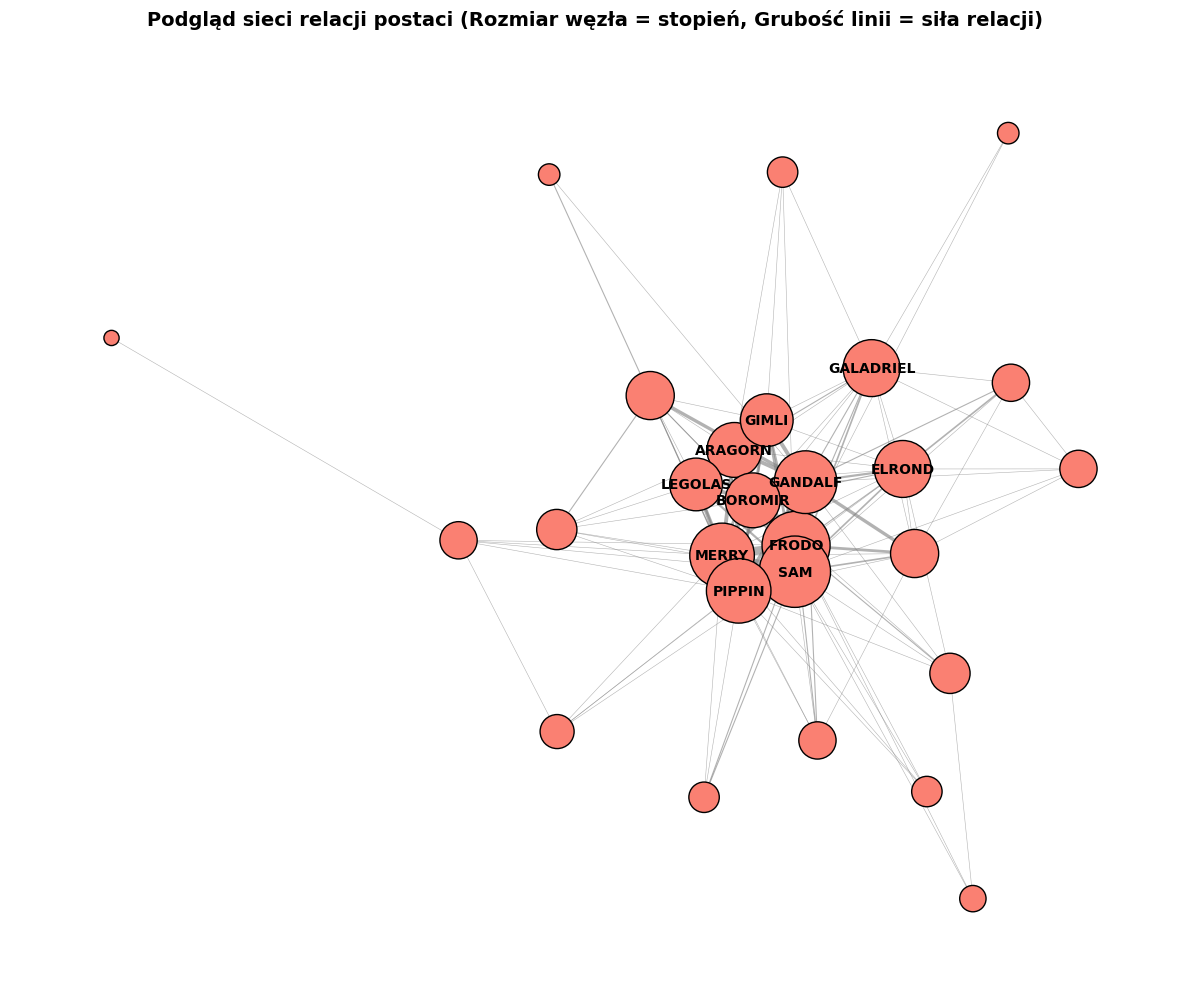

Podpowiedź: Etykiety zostały wyświetlone dla 10 kluczowych postaci (o stopniu >= 12), aby utrzymać czytelność rysunku.


In [26]:
import matplotlib.pyplot as plt
import networkx as nx

try:
    if 'G_postaci' in locals() and G_postaci is not None:
        # Obliczenie stopnia dla każdego węzła, aby dopasować wielkość punktów
        stopnie = dict(G_postaci.degree())

        # Rozmiar węzła proporcjonalny do jego stopnia
        node_sizes = [stopnie[node] * 120 for node in G_postaci.nodes()]

        # Grubość krawędzi proporcjonalna do wagi relacji
        weights = nx.get_edge_attributes(G_postaci, 'weight')
        edge_widths = [weights[edge] * 0.4 for edge in G_postaci.edges()]

        # Wybór układu grafu (layout spring_layout jest optymalny)
        plt.figure(figsize=(12, 10))
        pos = nx.spring_layout(G_postaci, k=0.45, seed=42)

        # Rysowanie węzłów i krawędzi
        nx.draw_networkx_nodes(G_postaci, pos, node_size=node_sizes, node_color='salmon', edgecolors='black')
        nx.draw_networkx_edges(G_postaci, pos, width=edge_widths, edge_color='gray', alpha=0.6)

        # Wyświetlanie etykiet tylko dla ważniejszych postaci (np. stopień >= 12)
        # aby uniknąć nakładania się tekstu i zachować pełną czytelność
        wazne_etykiety = {node: node for node in G_postaci.nodes() if stopnie[node] >= 12}
        nx.draw_networkx_labels(G_postaci, pos, labels=wazne_etykiety, font_size=10, font_weight='bold')

        plt.title('Podgląd sieci relacji postaci (Rozmiar węzła = stopień, Grubość linii = siła relacji)',
                  fontsize=14, fontweight='bold', pad=20)
        plt.axis('off')
        plt.tight_layout()
        plt.show()

        print("Podpowiedź: Etykiety zostały wyświetlone dla 10 kluczowych postaci (o stopniu >= 12), aby utrzymać czytelność rysunku.")
    else:
        print("Błąd: Obiekt sieci (G_postaci) jest pusty lub nie został zdefiniowany. Uruchom najpierw Krok 5A.")
except Exception as e:
    print(f"Wystąpił błąd podczas rysowania sieci: {e}")

#### Po uruchomieniu powinieneś zobaczyć


- Jeden rysunek sieci umieszczony bezpośrednio pod komórką.
- Większą widoczność postaci silniej osadzonych w sieci oraz wyraźniejsze relacje o większej sile.
- Krótką notę wyjaśniającą uproszczenie, jeśli sieć okaże się bardzo gęsta.


#### Pytanie interpretacyjne

Czy na podglądzie widać jednego głównego pośrednika, kilka grup postaci czy raczej gęstą strukturę bez wyraźnego centrum?


### Krok 5C. Eksport danych do dalszej analizy

#### Cel i sens analityczny

Ostatni krok przygotowuje dwa pliki, które można pobrać z Colab i analizować dalej w innych narzędziach.


#### Prompt dla modelu

```text
Kontekst:
Masz gotową tabelę relacji oraz zbudowaną sieć postaci.

Wejście:
Tabela relacji i gotowa sieć.

Zadanie:
Zapisz tabelę relacji do pliku `krawedzie.csv`, a całą sieć do pliku `graf_postaci.graphml`. Przed zapisaniem pliku GraphML upewnij się, że każdy węzeł ma ustawiony atrybut label, który zawiera czytelną nazwę postaci. Jeśli nazwa postaci jest już użyta jako identyfikator węzła, ustaw label na wartość identyczną z ID. Na końcu pokaż krótko, jakie pliki powstały i gdzie mozna je znaleźć w środowisku notatnika.

Pokaż wynik:
- komunikat o zapisaniu obu plików,
- listę nazw zapisanych plików,
- krótką wskazówkę, jak pobrać je z Colab.

Warunek poprawności:
Oba pliki powinny być niepuste i gotowe do otwarcia poza notatnikiem.

Jeśli wystąpi błąd:
Wyjaśnij, którego pliku nie udało się zapisać i z jakiego powodu.

Nie rób jeszcze:
Nie wykonuj już dalszej analizy.
```


In [27]:
import csv
import networkx as nx
import os

try:
    if 'tabela_relacji_lista' in locals() and 'G_postaci' in locals() and G_postaci is not None:
        # 1. Zapisywanie tabeli relacji do pliku krawedzie.csv
        sciezka_csv = 'krawedzie.csv'
        with open(sciezka_csv, mode='w', newline='', encoding='utf-8') as f_csv:
            writer = csv.writer(f_csv)
            # Zapis nagłówków
            writer.writerow(['Source', 'Target', 'Weight'])
            # Zapis wierszy relacji
            for relacja in tabela_relacji_lista:
                writer.writerow([relacja['postac_A'], relacja['postac_B'], relacja['sila_relacji']])

        # 2. Przygotowanie atrybutów węzłów (label) i zapis do graf_postaci.graphml
        # Kopiujemy graf, aby nie modyfikować oryginalnego obiektu G_postaci
        G_do_zapisu = G_postaci.copy()
        for node in G_do_zapisu.nodes():
            G_do_zapisu.nodes[node]['label'] = str(node)

        sciezka_graphml = 'graf_postaci.graphml'
        nx.write_graphml(G_do_zapisu, sciezka_graphml)

        # Sprawdzenie obecności i poprawności plików
        if os.path.exists(sciezka_csv) and os.path.exists(sciezka_graphml):
            print("Sukces: Oba pliki zostały pomyślnie zapisane!")
            print(f"- Plik CSV: {sciezka_csv} (Rozmiar: {os.path.getsize(sciezka_csv)} bajtów)")
            print(f"- Plik GraphML: {sciezka_graphml} (Rozmiar: {os.path.getsize(sciezka_graphml)} bajtów)\n")

            print("Wskazówka: Aby pobrać wygenerowane pliki na swój komputer:")
            print("1. Kliknij ikonę folderu w lewym panelu bocznym Google Colab (sekcja 'Pliki').")
            print("2. Znajdź pliki 'krawedzie.csv' oraz 'graf_postaci.graphml' na liście.")
            print("3. Kliknij trzy kropki obok wybranego pliku i wybierz opcję 'Pobierz'.")
        else:
            print("Błąd: Pliki nie zostały poprawnie utworzone.")

    else:
        print("Błąd: Tabela relacji lub obiekt sieci są puste. Upewnij się, że kroki 4B oraz 5A zostały wykonane.")
except Exception as e:
    print(f"Wystąpił błąd podczas eksportowania danych: {e}")

Sukces: Oba pliki zostały pomyślnie zapisane!
- Plik CSV: krawedzie.csv (Rozmiar: 2349 bajtów)
- Plik GraphML: graf_postaci.graphml (Rozmiar: 11589 bajtów)

Wskazówka: Aby pobrać wygenerowane pliki na swój komputer:
1. Kliknij ikonę folderu w lewym panelu bocznym Google Colab (sekcja 'Pliki').
2. Znajdź pliki 'krawedzie.csv' oraz 'graf_postaci.graphml' na liście.
3. Kliknij trzy kropki obok wybranego pliku i wybierz opcję 'Pobierz'.


#### Po uruchomieniu powinieneś zobaczyć


- Potwierdzenie zapisania plików `krawedzie.csv` i `graf_postaci.graphml`.
- Krótką listę lub komunikat pokazujący, że pliki są widoczne w środowisku notatnika.
- Jednozdaniową wskazówkę, jak pobrać pliki z Google Colab.


---
## Co dalej?

- Otwórz `graf_postaci.graphml` w Gephi albo innym narzędziu do analizy sieci, aby policzyć miary centralności i sprawdzić społeczności postaci.
- Otwórz `krawedzie.csv` w arkuszu kalkulacyjnym, jeśli chcesz filtrować, sortować i porównywać relacje bez pracy na grafie.
- Zmień adres scenariusza w komórce parametru i porównaj strukturę narracyjną różnych filmów.
- Jeśli któryś krok działa źle, poproś model o poprawienie tylko tego jednego fragmentu zamiast generowania całego rozwiązania od nowa.
